# Dataset audit and milestone analysis

**Ali Lordifar | Role 4 | October 18, 2026**

Kennedy owns the raw-data notebook, Aaron owns simulation and labels, and Noah owns preprocessing. My part is to check how their outputs fit together, summarize the data, and write the methodology plan.

I am using `manual_preprocessing_v1`. Kennedy's completed acquisition now covers all seven source groups. The exported pilot files have not been copied into this checkout. I keep those two kinds of evidence separate below. I do not use the earlier 800-per-run dataset or its model results to fill the gaps in this pilot.

## Load the available evidence

I read the other notebooks as JSON, without running or changing their code. Saved outputs show what was reported in those runs; they do not let me check the original arrays or reproduce an export. The file check below is the starting point for the local audit.

In [1]:
# Cell 3
from pathlib import Path
import json
import re
import io
import base64

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

project_root = Path.cwd().resolve()
while not (project_root / "requirements.txt").is_file():
    if project_root == project_root.parent:
        raise FileNotFoundError("Run this notebook from inside the project folder.")
    project_root = project_root.parent

notebook_dir = project_root / "notebooks" / "milestone_preprocessing_roles"
experiment_id = "manual_preprocessing_v1"
experiment_root = project_root / "artifacts" / "manual_preprocessing_milestone" / experiment_id

def read_notebook(filename):
    return json.loads((notebook_dir / filename).read_text())

kennedy = read_notebook("01_raw_data_provenance_and_eda.ipynb")
aaron = read_notebook("02_simulations_labels_and_selection.ipynb")
noah = read_notebook("03_preprocessing_and_quality_checks.ipynb")

def text_from_cell(notebook, code_fragment):
    matches = [cell for cell in notebook["cells"]
               if cell["cell_type"] == "code" and code_fragment in "".join(cell["source"])]
    if len(matches) != 1:
        raise ValueError(f"Expected one evidence cell for {code_fragment!r}; found {len(matches)}.")
    parts = []
    for output in matches[0].get("outputs", []):
        value = output.get("text", output.get("data", {}).get("text/plain", []))
        parts.append("".join(value))
    return "\n".join(parts)

required_files = [
    "data/experiment.json", "data/noise_manifest.csv",
    "data/acquisition_accounting.csv", "data/selection_ledger.csv",
    "simulation/attempts.csv", "simulation/injection_manifest.csv",
    "simulation/targets.csv", "preprocessing/processed_manifest.csv",
    "preprocessing/processed.npz", "preprocessing/rejections.csv",
    "preprocessing/processing_settings.json",
]
file_status = pd.DataFrame({"file": required_files})
file_status["available_here"] = [(experiment_root / name).is_file() for name in required_files]
display(file_status)

execution_status = []
for name, notebook in [("Kennedy", kennedy), ("Aaron", aaron), ("Noah", noah)]:
    code_cells = [cell for cell in notebook["cells"] if cell["cell_type"] == "code"]
    execution_status.append({
        "owner": name,
        "code_cells_with_saved_outputs": sum(bool(cell.get("outputs")) for cell in code_cells),
        "saved_error_outputs": sum(output.get("output_type") == "error"
                                   for cell in code_cells for output in cell.get("outputs", [])),
    })
display(pd.DataFrame(execution_status))

,file,available_here
0,data/experiment.json,False
1,data/noise_manifest.csv,False
2,data/acquisition_accounting.csv,False
3,data/selection_ledger.csv,False
4,simulation/attempts.csv,False
5,simulation/injection_manifest.csv,False
6,simulation/targets.csv,False
7,preprocessing/processed_manifest.csv,False
8,preprocessing/processed.npz,False
9,preprocessing/rejections.csv,False


,owner,code_cells_with_saved_outputs,saved_error_outputs
0,Kennedy,20,0
1,Aaron,6,0
2,Noah,0,0


## Raw-data accounting

Kennedy's updated run acquired and QC-accepted all seven source groups: three O3a training groups, one O3a validation group, one O3a test group and two O4a test groups. His EDA led to an additional transient screen and replacement of the validation source. I use the final source IDs, not the earlier handoff, for the current raw-data accounting.

In [2]:
# Cell 6
selection_text = text_from_cell(kennedy, "def nearest_exclusion_sec")
selected_rows = re.findall(
    r"^\s*\d+\s+(O3a|O4a)\s+(\S+)\s+(train|validation|O3a_test|O4a_test)\s+(\d+)\s+([\d.]+)\s*$",
    selection_text, re.MULTILINE,
)
selected_sources = pd.DataFrame(selected_rows, columns=[
    "run", "group_id", "split", "gps_start", "nearest_exclusion_h",
])
if selected_sources.empty:
    raise ValueError("The saved source-selection table was not found; review Kennedy's output format.")
selected_sources["gps_start"] = selected_sources["gps_start"].astype("int64")
selected_sources["nearest_exclusion_h"] = selected_sources["nearest_exclusion_h"].astype(float)
selected_sources["gps_end"] = selected_sources["gps_start"] + 512

export_text = text_from_cell(kennedy, "First handoff. Export")
reported_noise_ids = re.findall(r"^(H1_(?:O3a|O4a)_\d+): (?:written|unchanged)\s*$", export_text, re.MULTILINE)
if not reported_noise_ids:
    raise ValueError("No exported noise IDs found in the saved handoff output.")
selected_sources["noise_id"] = [f"H1_{row.run}_{row.gps_start}" for row in selected_sources.itertuples()]
selected_sources["reported_exported"] = selected_sources["noise_id"].isin(reported_noise_ids)
selected_sources["local_array_available"] = [
    (experiment_root / "data" / "noise" / f"{noise_id}.npy").is_file()
    for noise_id in selected_sources["noise_id"]
]

qc_text = text_from_cell(kennedy, "QC_ROWS = []")
if "2097152" not in qc_text or "passed R1-R5" not in qc_text:
    raise ValueError("Review the source QC evidence before using the reported acquisition counts.")
reported_raw = selected_sources.loc[selected_sources["reported_exported"]].copy()
reported_raw["duration_sec"] = 512
reported_raw["n_samples"] = 512 * 4096
source_counts = selected_sources.groupby(["run", "split"]).agg(
    selected_groups=("group_id", "size"),
    reported_exported_groups=("reported_exported", "sum"),
    local_arrays=("local_array_available", "sum"),
).reindex(pd.MultiIndex.from_tuples([
    ("O3a", "train"), ("O3a", "validation"), ("O3a", "O3a_test"), ("O4a", "O4a_test"),
], names=["run", "split"]), fill_value=0)
display(source_counts)
display(reported_raw[["noise_id", "group_id", "split", "duration_sec", "n_samples"]])
print(f"Reported QC-accepted raw data: {reported_raw.duration_sec.sum():,} seconds; "
      f"{reported_raw.n_samples.sum():,} strain samples.")
assert len(reported_raw) == len(selected_sources) == 7
assert reported_raw.duration_sec.sum() == 3584
assert reported_raw.n_samples.sum() == 14680064
print("Evidence: Kennedy's updated QC/export output; local arrays remain unavailable.")

obsolete_names = ["H1_O3a_1249235008.npy", "H1_O3a_1249239104.npy"]
for name in obsolete_names:
    old_path = experiment_root / "data/noise" / name
    print(f"Retired source {name}: {'present; exclude from the manifest' if old_path.exists() else 'not present here'}")
validation_source = selected_sources.loc[selected_sources["split"] == "validation", "noise_id"].item()
assert validation_source == "H1_O3a_1249325120"
print("Current validation source:", validation_source)

selected_groups  reported_exported_groups  local_arrays
run split                                                              
O3a train                     3                         3             0
    validation                1                         1             0
    O3a_test                  1                         1             0
O4a O4a_test                  2                         2             0

,noise_id,group_id,split,duration_sec,n_samples
0,H1_O3a_1239760960,O3a_g01,train,512,2097152
1,H1_O3a_1242927168,O3a_g02,train,512,2097152
2,H1_O3a_1246081088,O3a_g03,train,512,2097152
3,H1_O3a_1249325120,O3a_g04,validation,512,2097152
4,H1_O3a_1252397120,O3a_g05,O3a_test,512,2097152
5,H1_O4a_1374097472,O4a_g01,O4a_test,512,2097152
6,H1_O4a_1384337472,O4a_g02,O4a_test,512,2097152


Reported QC-accepted raw data: 3,584 seconds; 14,680,064 strain samples.
Evidence: Kennedy's updated QC/export output; local arrays remain unavailable.
Retired source H1_O3a_1249235008.npy: not present here
Retired source H1_O3a_1249239104.npy: not present here
Current validation source: H1_O3a_1249325120


The updated handoff accounts for **3,584 seconds and 14,680,064 raw strain samples**, all from seven 512-second crops. O3a contributes 2,560 seconds; O4a contributes 1,024 seconds. These are raw time samples, not labeled ML examples.

Kennedy added R5 after inspecting the data: reject a candidate if any eight-second block has a standard deviation greater than three times the window's median block standard deviation. The source ledger reports 36 O3a candidates: 26 outside the required quality intervals, five rejected by R5 and five retained. Both O4a candidates were retained. Rejected windows were replaced, not clipped or interpolated.

The final O3a validation source is `H1_O3a_1249325120.npy`. The retired `H1_O3a_1249235008.npy` and `H1_O3a_1249239104.npy` files are absent locally. Local consumers must use the new manifest rather than loading every file in the noise directory. Passing R1–R5 still does not establish that the data are free of every transient.

## Review the completed raw-data EDA

Kennedy's saved summary gives a near-zero skew for each source, but the distribution shapes and amplitude scales differ. I read the rounded statistics from that output below. This is a review of his measurements; I am not recomputing statistics from missing arrays.

,group_id,run,split,mean,std,skewness,excess_kurtosis
0,O3a_g01,O3a,train,-1.367000e-23,3.527000e-19,0.000046,-1.31200
1,O3a_g02,O3a,train,4.476000e-25,8.127000e-20,-0.000482,0.03555
2,O3a_g03,O3a,train,1.260000e-25,6.405000e-20,0.000689,0.01194
3,O3a_g04,O3a,validation,-2.102000e-24,7.404000e-20,-0.000279,0.15200
4,O3a_g05,O3a,O3a_test,-4.312000e-26,7.005000e-20,-0.000184,0.03987
5,O4a_g01,O4a,O4a_test,-1.271000e-22,1.465000e-18,-0.000178,0.64560
6,O4a_g02,O4a,O4a_test,1.408000e-24,1.051000e-18,-0.000922,0.27440


Median raw std from rounded saved values: {'O3a': 7.404e-20, 'O4a': 1.258e-18}


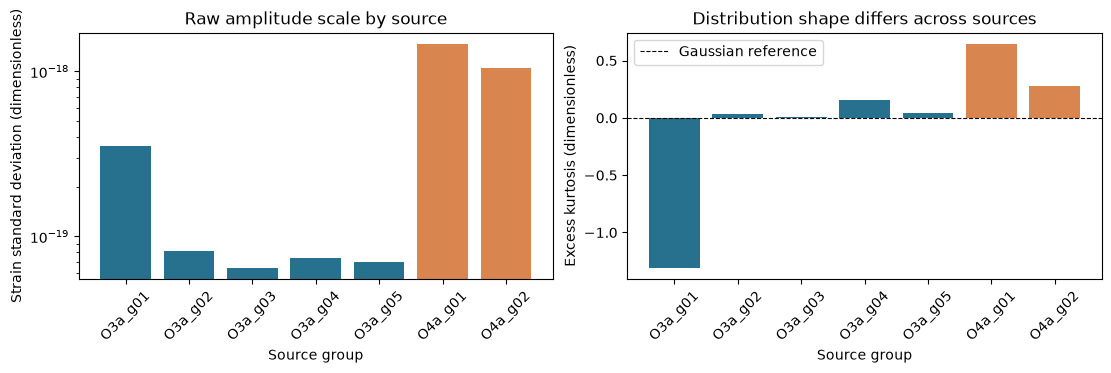

,group_id,run,block_std_median,block_std_max_over_min,block_std_cv
0,O3a_g01,O3a,3.540000e-19,1.24,0.0432
1,O3a_g02,O3a,7.890000e-20,1.95,0.1480
2,O3a_g03,O3a,6.360000e-20,1.75,0.1260
3,O3a_g04,O3a,7.350000e-20,1.53,0.0985
4,O3a_g05,O3a,6.940000e-20,1.70,0.0960
5,O4a_g01,O4a,1.420000e-18,2.32,0.1860
6,O4a_g02,O4a,1.020000e-18,2.15,0.1630


In [3]:
# Cell 9
raw_eda_text = text_from_cell(kennedy, "EDA_SUMMARY = pd.DataFrame")
number = r"[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?"
pattern = (rf"^\s*\d+\s+(O[34]a_g\d+)\s+(O3a|O4a)\s+"
           rf"(train|validation|O3a_test|O4a_test)\s+({number})\s+({number})\s+({number})\s+({number})\s*$")
eda_rows = re.findall(pattern, raw_eda_text, re.MULTILINE)
raw_eda = pd.DataFrame(eda_rows, columns=[
    "group_id", "run", "split", "mean", "std", "skewness", "excess_kurtosis",
])
assert len(raw_eda) == 7 and raw_eda["group_id"].is_unique
assert set(raw_eda["group_id"]) == set(selected_sources["group_id"])
for column in ["mean", "std", "skewness", "excess_kurtosis"]:
    raw_eda[column] = raw_eda[column].astype(float)
display(raw_eda)
print("Median raw std from rounded saved values:", raw_eda.groupby("run")["std"].median().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
colors = raw_eda["run"].map({"O3a": "#28718e", "O4a": "#d98550"})
axes[0].bar(raw_eda["group_id"], raw_eda["std"], color=colors)
axes[0].set(yscale="log", title="Raw amplitude scale by source", xlabel="Source group",
            ylabel="Strain standard deviation (dimensionless)")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(raw_eda["group_id"], raw_eda["excess_kurtosis"], color=colors)
axes[1].axhline(0, color="black", linewidth=0.8, linestyle="--", label="Gaussian reference")
axes[1].set(title="Distribution shape differs across sources", xlabel="Source group",
            ylabel="Excess kurtosis (dimensionless)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.show()

block_text = text_from_cell(kennedy, "stability = pd.DataFrame")
stability_rows = re.findall(
    rf"^\s*\d+\s+(O[34]a_g\d+)\s+(O3a|O4a)\s+({number})\s+({number})\s+({number})\s*$",
    block_text, re.MULTILINE,
)
stability = pd.DataFrame(stability_rows, columns=[
    "group_id", "run", "block_std_median", "block_std_max_over_min", "block_std_cv",
])
assert len(stability) == 7
for column in stability.columns[2:]:
    stability[column] = stability[column].astype(float)
display(stability)

The median raw standard deviations reported by Kennedy are about **7.404 × 10⁻²⁰ for O3a** and **1.258 × 10⁻¹⁸ for O4a**. This is a raw broadband statistic, not a measure of sensitivity across the analysis band.

`O3a_g01` has excess kurtosis about −1.312, unlike a Gaussian distribution; the two O4a values are about 0.646 and 0.274. Near-zero skew alone does not make these distributions Gaussian. Eight-second block standard deviations vary within windows: max/min ratios range from 1.24 to 1.95 for the O3a examples and 2.15 to 2.32 for O4a. The R5 screen removes large blockwise excursions but does not make the retained noise stationary.

Kennedy's separate BURST_CAT2 check is not uniformly clean across the windows. That flag is not part of the required CBC-focused acceptance rule. The report should describe the exact rules used rather than claim that every burst veto passed.

## Injection accounting and selection

Aaron's saved output reports 100 attempted injections. I read the per-run counts from that table and check that they reconcile with the printed totals. I have not loaded his exported buffers here.

status,run,split,accepted,rejected,failed,attempted,acceptance_pct
0,O3a,train,44,6,0,50,88.0
1,O4a,O4a_test,9,41,0,50,18.0


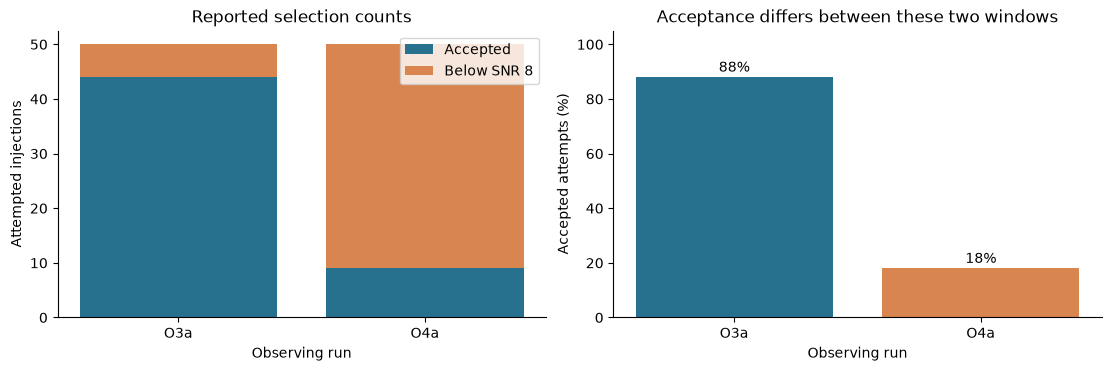

In [4]:
# Cell 12
attempt_text = text_from_cell(aaron, "Reference library SNR:")
selection_rows = re.findall(
    r"^\s*\d+\s+(O3a|O4a)\s+(train|validation|O3a_test|O4a_test)\s+(accepted|rejected|failed)\s+(\d+)\s*$",
    attempt_text, re.MULTILINE,
)
selection_counts = pd.DataFrame(selection_rows, columns=["run", "split", "status", "count"])
if selection_counts.empty:
    raise ValueError("No saved injection-count table found.")
selection_counts["count"] = selection_counts["count"].astype(int)
reported_injections = selection_counts.pivot_table(
    index=["run", "split"], columns="status", values="count", aggfunc="sum", fill_value=0,
).reindex(columns=["accepted", "rejected", "failed"], fill_value=0)
reported_injections["attempted"] = reported_injections.sum(axis=1)
reported_injections["acceptance_pct"] = 100 * reported_injections["accepted"] / reported_injections["attempted"]
for label, column in [("Attempted", "attempted"), ("Accepted", "accepted"), ("Rejected", "rejected"), ("Failed", "failed")]:
    match = re.search(rf"^{label}:\s*(\d+)\s*$", attempt_text, re.MULTILINE)
    if match is None or int(match.group(1)) != int(reported_injections[column].sum()):
        raise ValueError(f"The saved {label.lower()} total does not reconcile.")
display(reported_injections.reset_index())

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
plot_counts = reported_injections.reset_index()
axes[0].bar(plot_counts["run"], plot_counts["accepted"], label="Accepted", color="#28718e")
axes[0].bar(plot_counts["run"], plot_counts["rejected"], bottom=plot_counts["accepted"],
            label="Below SNR 8", color="#d98550")
axes[0].set(title="Reported selection counts", xlabel="Observing run", ylabel="Attempted injections")
axes[0].legend()
axes[1].bar(plot_counts["run"], plot_counts["acceptance_pct"], color=["#28718e", "#d98550"])
for i, value in enumerate(plot_counts["acceptance_pct"]):
    axes[1].text(i, value + 2, f"{value:.0f}%", ha="center")
axes[1].set(title="Acceptance differs between these two windows", xlabel="Observing run",
            ylabel="Accepted attempts (%)", ylim=(0, 105))
plt.show()

The counts reconcile: **44 O3a training injections and 9 O4a test injections were accepted**, with 47 rejected and no reported failures. Both runs had 50 attempts, giving acceptance rates of 88% and 18%.

These counts belong to Aaron's earlier two-source subset, using the unchanged O3a_g01 and O4a_g01 sources. They are not the result of generating injections across Kennedy's seven-source handoff. This is a comparison of one background per run, with different parameter draws assigned to each. It does not establish a run-wide sensitivity difference or model drift. SNR selection also changes which physical systems remain in the labeled dataset. These pilot results must not be mixed with the earlier 800-per-run experiment.

## Check the local handoff when it arrives

This section uses the actual CSV and NPZ files if they are available. It checks IDs, source groups, label order, sample counts and rejection accounting. Until then, its status stays pending. It does not generate replacement data or write into another owner's folders.

In [5]:
# Cell 15
targets_order = ["chirp_mass", "mass_ratio", "chi_eff", "distance"]
processed_data = None
joined = None
local_split_counts = None
local_audit_passed = False
needed = ["data/experiment.json", "data/noise_manifest.csv", "simulation/attempts.csv",
          "simulation/injection_manifest.csv", "simulation/targets.csv",
          "preprocessing/processed_manifest.csv", "preprocessing/processed.npz",
          "preprocessing/rejections.csv", "preprocessing/processing_settings.json"]
missing = [name for name in needed if not (experiment_root / name).is_file()]

if missing:
    print("Local dataset audit pending. Missing files:")
    for name in missing:
        print(" -", name)
else:
    experiment = json.loads((experiment_root / "data/experiment.json").read_text())
    settings = json.loads((experiment_root / "preprocessing/processing_settings.json").read_text())
    assert experiment["experiment_id"] == settings["experiment_id"] == experiment_id
    assert settings["sample_rate_hz"] == 4096 and settings["window_samples"] == 16384
    assert settings["target_order"] == targets_order
    noise = pd.read_csv(experiment_root / "data/noise_manifest.csv")
    current_ids = set(selected_sources["noise_id"])
    assert set(noise["noise_id"]) == current_ids, "Local noise manifest does not match Kennedy's latest source list"
    current_sources = selected_sources.set_index("noise_id")
    for row in noise.itertuples():
        expected = current_sources.loc[row.noise_id]
        assert row.group_id == expected.group_id and row.split == expected.split
        assert row.gps_start == expected.gps_start and row.gps_end == expected.gps_end
    attempts = pd.read_csv(experiment_root / "simulation/attempts.csv")
    injections = pd.read_csv(experiment_root / "simulation/injection_manifest.csv")
    targets = pd.read_csv(experiment_root / "simulation/targets.csv")
    processed = pd.read_csv(experiment_root / "preprocessing/processed_manifest.csv")
    rejections = pd.read_csv(experiment_root / "preprocessing/rejections.csv")
    for frame, key in [(noise, "noise_id"), (attempts, "attempt_id"),
                       (injections, "sample_id"), (targets, "sample_id"), (processed, "sample_id")]:
        assert frame[key].notna().all() and frame[key].is_unique, f"Invalid {key} values"
    assert attempts["status"].isin(["accepted", "rejected", "failed"]).all()
    accepted_attempts = attempts.loc[attempts["status"] == "accepted"]
    assert accepted_attempts["sample_id"].is_unique
    assert set(accepted_attempts["sample_id"]) == set(injections["sample_id"]) == set(targets["sample_id"])
    assert (accepted_attempts["snr"] >= 8).all()
    assert rejections["sample_id"].is_unique
    retained_ids = set(processed["sample_id"])
    rejected_ids = set(rejections["sample_id"])
    assert not retained_ids & rejected_ids
    assert retained_ids | rejected_ids == set(injections["sample_id"])
    assert not noise.groupby("group_id")["split"].nunique().gt(1).any()
    assert not noise.loc[noise["run"] == "O4a", "split"].ne("O4a_test").any()
    for run, group in noise.groupby("run"):
        ordered = group.sort_values("gps_start")
        intervals = ordered[["gps_start", "gps_end"]].to_numpy()
        assert (intervals[:, 1] > intervals[:, 0]).all()
        assert np.all(intervals[1:, 0] >= intervals[:-1, 1]), "Raw source intervals overlap"
    for row in noise.loc[noise["quality_status"] == "accepted"].itertuples():
        raw = np.load(project_root / row.strain_path, allow_pickle=False, mmap_mode="r")
        assert raw.shape == (int(row.n_samples),) and np.isfinite(raw).all()
        assert np.isclose(row.n_samples / row.sample_rate_hz, row.gps_end - row.gps_start)
    provenance = injections.merge(noise[["noise_id", "group_id", "run", "split"]],
                                   on="noise_id", validate="many_to_one", suffixes=("", "_source"), indicator=True)
    assert provenance["_merge"].eq("both").all()
    for column in ["group_id", "run", "split"]:
        assert provenance[column].eq(provenance[column + "_source"]).all()
    processed = processed.sort_values("row_index")
    assert np.array_equal(processed["row_index"], np.arange(len(processed)))
    retained = processed.merge(injections[["sample_id", "noise_id", "group_id", "run", "split"]],
                               on="sample_id", validate="one_to_one", suffixes=("", "_injection"), indicator=True)
    assert retained["_merge"].eq("both").all()
    for column in ["noise_id", "group_id", "run", "split"]:
        assert retained[column].eq(retained[column + "_injection"]).all()
    joined = processed.merge(targets[["sample_id", *targets_order]], on="sample_id",
                             validate="one_to_one", suffixes=("_manifest", ""), indicator=True)
    assert joined["_merge"].eq("both").all()
    for noise_id, rows in processed.groupby("noise_id"):
        intervals = rows.sort_values("crop_start_in_noise_samples")[[
            "crop_start_in_noise_samples", "crop_stop_in_noise_samples"]].to_numpy()
        assert np.all(intervals[:, 1] - intervals[:, 0] == 16384)
        assert np.all(intervals[1:, 0] >= intervals[:-1, 1]), "Final crop windows overlap"
    with np.load(experiment_root / "preprocessing/processed.npz", allow_pickle=False) as data:
        processed_data = {key: data[key].copy() for key in data.files}
    assert np.array_equal(processed_data["sample_id"], processed["sample_id"].to_numpy())
    assert np.array_equal(processed_data["split"], processed["split"].to_numpy())
    assert processed_data["X"].shape == (len(processed), 16384)
    assert processed_data["theta"].shape == (len(processed), 4)
    assert np.isfinite(processed_data["X"]).all() and np.isfinite(processed_data["theta"]).all()
    assert np.allclose(processed_data["theta"], joined[targets_order].to_numpy())
    local_split_counts = processed.groupby(["run", "split"]).agg(
        final_examples=("sample_id", "size"), source_groups=("group_id", "nunique"))
    display(local_split_counts)
    local_audit_passed = True
    print("The local ID, provenance, shape, label and split checks passed.")

Local dataset audit pending. Missing files:
 - data/experiment.json
 - data/noise_manifest.csv
 - simulation/attempts.csv
 - simulation/injection_manifest.csv
 - simulation/targets.csv
 - preprocessing/processed_manifest.csv
 - preprocessing/processed.npz
 - preprocessing/rejections.csv
 - preprocessing/processing_settings.json


**Cell 16**

There is no verified processed example count here yet. All seven raw source groups are now reported acquired, including validation and O3a testing. Aaron's saved simulation run still covers only the first training group and first O4a group. The new raw-source availability must not be mistaken for completed injection or preprocessing counts in every split.

The local audit checks the current seven source IDs as well as the downstream row/label contracts. It will reject an earlier validation manifest rather than silently accepting it.

**Cell 17**

## Input summaries and feature–target relationships

Once the processed inputs pass the audit, I will compare RMS, peak amplitude, spectral centroid and three band powers with the four targets. These summaries use the same whitening and filtering convention for every row. I use only O3a development data here; held-out rows are not used to select features.

The code is ready below, but without Noah's arrays there is no new waveform–target result to report. Correlation measures association, not model feature importance.

In [6]:
# Cell 18
feature_summary = None
feature_correlations = None
if not local_audit_passed:
    print("Feature EDA pending: no locally audited processed dataset.")
else:
    development = joined["run"].eq("O3a") & joined["split"].isin(["train", "validation"])
    X = processed_data["X"][development.to_numpy()]
    labels = joined.loc[development, ["sample_id", "split", *targets_order]].reset_index(drop=True)
    if len(X) < 3:
        print("Too few O3a development examples for a useful correlation analysis.")
    else:
        frequencies = np.fft.rfftfreq(X.shape[1], d=1 / 4096)
        fft_power = np.abs(np.fft.rfft(X, axis=1)) ** 2
        band = (frequencies >= 35) & (frequencies <= 350)
        total = fft_power[:, band].sum(axis=1)
        assert (total > 0).all()
        summary = {
            "rms": np.sqrt(np.mean(X ** 2, axis=1)),
            "peak_abs": np.max(np.abs(X), axis=1),
            "centroid_hz": (fft_power[:, band] * frequencies[band]).sum(axis=1) / total,
        }
        for low, high in [(35, 80), (80, 150), (150, 350)]:
            mask = (frequencies >= low) & ((frequencies <= high) if high == 350 else (frequencies < high))
            summary[f"relative_power_{low}_{high}"] = fft_power[:, mask].sum(axis=1) / total
        feature_summary = pd.concat([labels, pd.DataFrame(summary)], axis=1)
        feature_names = list(summary)
        feature_correlations = feature_summary[feature_names + targets_order].corr(method="spearman").loc[feature_names, targets_order]
        display(feature_correlations.round(3))
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
        axes[0].scatter(feature_summary["distance"], feature_summary["rms"], alpha=0.6, s=20)
        axes[0].set(title=f"Distance and processed amplitude (N={len(X)})",
                    xlabel="True distance (Mpc)", ylabel="RMS (whitened units)")
        image = axes[1].imshow(feature_correlations, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
        axes[1].set_xticks(range(4), targets_order, rotation=25, ha="right")
        axes[1].set_yticks(range(len(feature_names)), feature_names)
        axes[1].set(title="Feature–target associations", xlabel="Target", ylabel="Waveform summary")
        fig.colorbar(image, ax=axes[1], label="Spearman correlation")
        plt.show()

Feature EDA pending: no locally audited processed dataset.


RMS and peak amplitude retain the processed waveform's amplitude scale. Spectral centroid is in Hz; relative band powers are dimensionless fractions. I have not applied per-example amplitude normalization because it could remove information relevant to distance.

Model-based importance remains unfinished. After fitting a simple baseline on independent training groups, I would measure permutation importance on validation summaries and report the scoring rule and variability. That is outside the current no-training scope, so the report should acknowledge this rubric gap rather than label correlation as importance.

## Review the EDA already available

Aaron's saved figures show the accepted target distributions, selection effects, target correlations and distance versus SNR. I include two of his figures below as reviewed team evidence, not as plots I computed from local data. Their exact values cannot be independently recalculated until his CSV files arrive.

**Aaron's accepted-target distributions (53 accepted injections).**

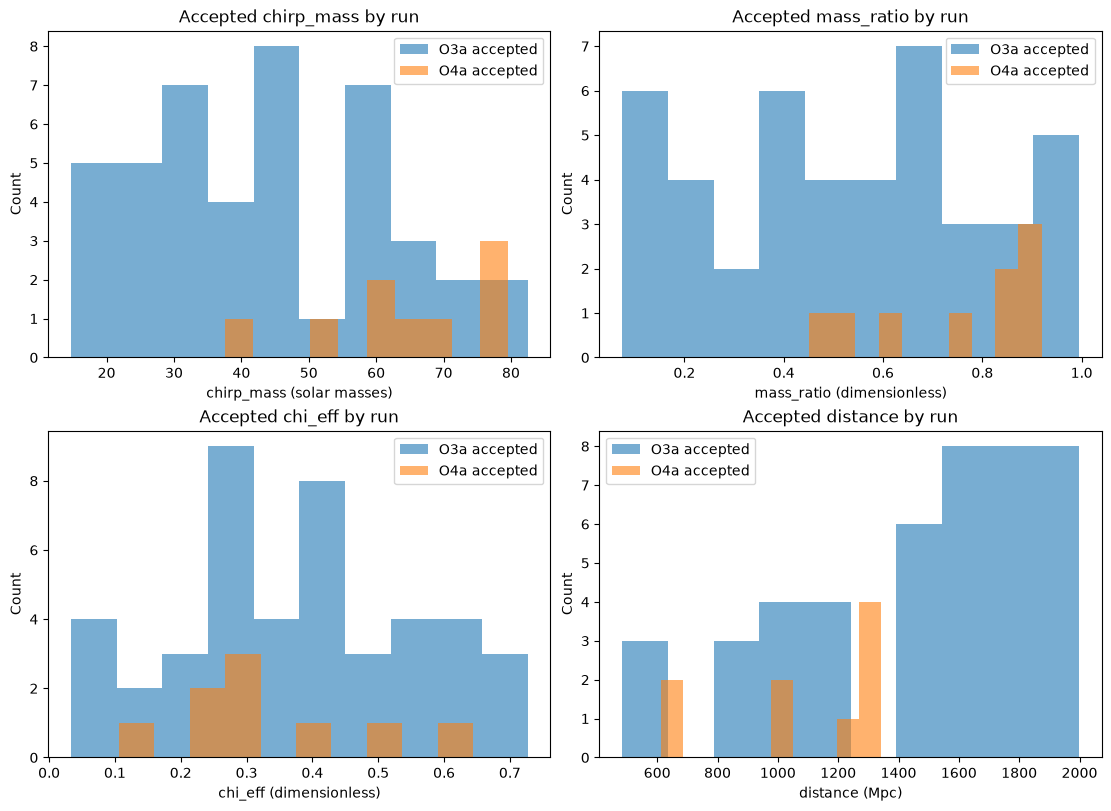

**Aaron's distance–SNR plot (100 attempts; both runs).**

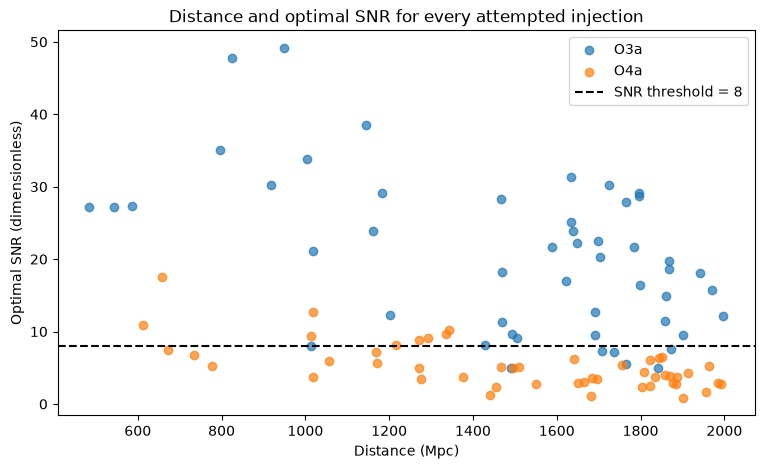

In [7]:
# Cell 21
analysis_cells = [cell for cell in aaron["cells"] if cell["cell_type"] == "code"
                  and "accepted_analysis =" in "".join(cell["source"])]
assert len(analysis_cells) == 1
team_figures = [output["data"]["image/png"] for output in analysis_cells[0].get("outputs", [])
                if "image/png" in output.get("data", {})]
if len(team_figures) < 4:
    print("Aaron's expected EDA figures are not all available in the saved outputs.")
else:
    display(Markdown("**Aaron's accepted-target distributions (53 accepted injections).**"))
    display(Image(data=base64.b64decode("".join(team_figures[0])), width=700))
    display(Markdown("**Aaron's distance–SNR plot (100 attempts; both runs).**"))
    display(Image(data=base64.b64decode("".join(team_figures[3])), width=700))

These are small selected populations, especially the nine accepted O4a examples. The distributions describe the earlier two-source injection subset, not all seven current source groups, and should be interpreted with that sample size in mind. Spins are restricted to positive aligned values by the simulation draws, so they do not represent a general spin population. Distance uses Euclidean volume weighting over 100–2,000 Mpc, not an exact cosmological comoving-volume prior.

The distance–SNR plot also varies mass and spin. It cannot isolate distance's effect on detectability. Aaron's fixed-parameter distance comparison is the cleaner controlled exercise: the saved peak amplitudes at 100, 500 and 1,000 Mpc are consistent with inverse-distance scaling.

## Plan for the model comparison

I will use linear regression as the baseline and a training-mean predictor as a reference. Ridge is the small regularized improvement: the first alpha grid will be 0.1, 1, 10, 100 and 1,000. The second improvement is SNPE with a masked autoregressive flow, which estimates a joint posterior rather than a single value. These are planned comparisons, not model results from this pilot.

Before fitting, we need training, validation and within-run test examples from separate source groups. Scaling is fitted on training rows only. I will choose Ridge's alpha on O3a validation, compare the same examples and target order, and report per-target MAE, RMSE and R-squared with units. If I combine target errors, I will normalize by a training-only target scale so distance does not dominate. A negative R-squared is a meaningful comparison with a constant reference, not a value to hide.

For SNPE, we need recorded architecture, learning rate, batch size, validation fraction, early-stopping rule and seed. A small validation-based trial comes before a broader search. I would compare posterior means with the regression predictions, then assess central 50%, 80% and 90% interval coverage, interval widths and sampling failures. Runs need comparable sample budgets.

The inference prior needs special care: uniform component draws do not produce a uniform box over chirp mass, mass ratio and effective spin, and the SNR gate changes the accepted population again. I will agree on that sampling/inference contract with Aaron before calling rank tests formal SBC. With one current background per run, noise, source selection and sampling variability are confounded; no cross-run calibration conclusion is justified. A fresh final test is needed if held-out examples are used during development.

## What can go into the milestone now?

I distinguish implemented code, saved execution evidence and locally checked artifacts. The report should describe this manual pilot rather than inherit the earlier full-pipeline counts.

In [8]:
# Cell 25
milestone_status = pd.DataFrame([
    ("Source selection", "Saved output", "7 groups reported fetched, QC accepted and exported; validation source replaced"),
    ("Raw pilot size", "Saved output", "7 × 512 s at 4096 Hz; 14,680,064 samples"),
    ("Injection accounting", "Saved output", "Earlier two-source subset: 100 attempts = 53 accepted + 47 rejected + 0 failed"),
    ("Current accepted allocation", "Saved output", "44 O3a train; 9 O4a_test; no validation/O3a_test injections shown"),
    ("Processed array handoff", "Pending local evidence", "No processed.npz or processed manifest available here"),
    ("Exact final split sizes", "Pending", "Cannot replace postprocessing counts with injection counts"),
    ("Input–target EDA", "Code prepared; not run on real inputs", "Requires locally audited processed rows"),
    ("Feature importance", "Pending", "Needs a fitted model and validation data"),
    ("Model comparison", "Planned", "Linear regression, Ridge, SNPE/MAF; no pilot model scores"),
], columns=["item", "evidence", "finding_or_next_step"])
display(milestone_status)

contributions = pd.DataFrame([
    ("Kennedy Goliman", "01", "Completed seven-source acquisition, R5 cleanup, raw EDA, split/export evidence"),
    ("Aaron Rassiq", "02", "Parameter draws, waveforms, injection/SNR accounting and saved EDA"),
    ("Noah Fonck", "03", "Preprocessing implementation; saved execution evidence pending"),
    ("Ali Lordifar", "04", "Notebook-output audit, count reconciliation, selection plots and methodology plan"),
], columns=["owner", "notebook", "work_visible_in_this_checkout"])
display(contributions)

,item,evidence,finding_or_next_step
0,Source selection,Saved output,"7 groups reported fetched, QC accepted and exp..."
1,Raw pilot size,Saved output,"7 × 512 s at 4096 Hz; 14,680,064 samples"
2,Injection accounting,Saved output,Earlier two-source subset: 100 attempts = 53 a...
3,Current accepted allocation,Saved output,44 O3a train; 9 O4a_test; no validation/O3a_te...
4,Processed array handoff,Pending local evidence,No processed.npz or processed manifest availab...
5,Exact final split sizes,Pending,Cannot replace postprocessing counts with inje...
6,Input–target EDA,Code prepared; not run on real inputs,Requires locally audited processed rows
7,Feature importance,Pending,Needs a fitted model and validation data
8,Model comparison,Planned,"Linear regression, Ridge, SNPE/MAF; no pilot m..."


,owner,notebook,work_visible_in_this_checkout
0,Kennedy Goliman,01,"Completed seven-source acquisition, R5 cleanup..."
1,Aaron Rassiq,02,"Parameter draws, waveforms, injection/SNR acco..."
2,Noah Fonck,03,Preprocessing implementation; saved execution ...
3,Ali Lordifar,04,"Notebook-output audit, count reconciliation, s..."


My audit reconciles Kennedy's updated seven-source acquisition with Aaron's earlier two-source injection run. Those are different stages of the same pilot, not interchangeable dataset sizes. I also checked the replacement validation ID and reviewed the raw-data distribution and blockwise-variation results.

The exported arrays and tables are still absent locally. Once those files arrive, the local audit and processed-input EDA can run without using the historical 800-per-run dataset. Model-based importance and final postprocessing split counts remain unmeasured. The report states those limits directly.

Kennedy, Aaron and Noah retain ownership of their notebooks; I have not changed or executed their implementations. The methodology remains linear regression, Ridge and SNPE/MAF, with fitting and validation after the dataset handoff.